# Physics-Informed Neural Networks for the 1D heat equation

Tutorial 3 of the ETH course *AI in the Sciences and Engineering* (which I'm auditing).
The base notebook and the task description come from the course materials;
I completed the exercises and slightly extended the notebook.

**Changes compared to the original tutorial notebook:**
- filled in the exercise parts (data generation, PDE residual, loss, training loop),
- type hints and docstrings, small cleanup,
- loss components (`mse_sb`, `mse_tb`, `mse_pde`) logged during training and plotted,
- optional switch for the `log10` wrapper and the `lambda_u` weight,
- a short **Further exploration** section at the end.

## Base lecture

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from tqdm import tqdm

torch.manual_seed(128)

#### Base MLP definition

In [2]:
class NeuralNet(nn.Module):

    def __init__(
        self,
        input_dimension: int,
        output_dimension: int,
        n_hidden_layers: int,
        hidden_dimension: int,
        regularization_param: float,
        regularization_exp: float,
        retrain_seed: int,
    ):
        super(NeuralNet, self).__init__()
        self.input_dimension = input_dimension
        self.output_dimension = output_dimension
        self.hidden_dimension = hidden_dimension
        self.n_hidden_layers = n_hidden_layers
        self.activation = nn.Tanh()
        self.regularization_param = regularization_param
        self.regularization_exp = regularization_exp

        self.input_layer = nn.Linear(self.input_dimension, self.hidden_dimension)
        self.hidden_layers = nn.ModuleList(
            [nn.Linear(self.hidden_dimension, self.hidden_dimension) for _ in range(n_hidden_layers - 1)]
        )
        self.output_layer = nn.Linear(self.hidden_dimension, self.output_dimension)
        self.retrain_seed = retrain_seed
        self.init_xavier()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.activation(self.input_layer(x))
        for k, l in enumerate(self.hidden_layers):
            x = self.activation(l(x))
        return self.output_layer(x)

    def init_xavier(self) -> None:
        torch.manual_seed(self.retrain_seed)

        def init_weights(m: nn.Module) -> None:
            if type(m) == nn.Linear and m.weight.requires_grad and m.bias.requires_grad:
                g = nn.init.calculate_gain("tanh")
                torch.nn.init.xavier_uniform_(m.weight, gain=g)
                # torch.nn.init.xavier_normal_(m.weight, gain=g)
                m.bias.data.fill_(0)

        self.apply(init_weights)

    def regularization(self) -> torch.Tensor:
        reg_loss = 0
        for name, param in self.named_parameters():
            if "weight" in name:
                reg_loss = reg_loss + torch.norm(param, self.regularization_exp)
        return self.regularization_param * reg_loss


### The task

Consider the one-dimensional heat equation:

$$
u_t(t, x) = u_{xx}(t, x), \quad t\in[0,T], ~x\in [-1,1]
$$


with zero Dirichlet boundary conditions

$$
u_b(t, -1)=u_b(t,1)=0,
$$

and initial condition

$$
u(x, 0) = u_0(x) = - \sin(\pi x)
$$

We want to obtain an approximate solution of the heat equation $u : [0,T]\times[-1,1] \mapsto \mathbb{R}$ with physics informed neural networks (PINNs).

To do so, we approximate the underlying solution with a feedforward dense neural network with tunable parameters $\theta$:

$$
u_\theta(t,x) \approx u(t,x)
$$
Define the following residuals:

   - Interior residual given by,

   $$r_{int,\theta}(t, x):=  u_{\theta, t}(x,t) - u_{\theta, xx}(x,t), \quad \forall ~t \in [0,T],~ x \in [-1,1].$$
   
        
      
        
   - Spatial boundary residual given by,
   
        $$r_{sb,\theta}(t,-1):= u_{\theta}(t,-1)- u_b(t,-1), \quad r_{sb,\theta}(t,1):= u_{\theta}(t,1)- u_b(t,1), \quad \forall t \in (0,T].$$
        
   - Temporal boundary residual given by,
   
        $$r_{tb,\theta}(x):= u_{\theta}(x,0) - u_0(x), \quad \forall x \in [-1,1].$$

and compute the corresponding loss functions:

$$
L_{int}(\theta) = \int_{[0,T]\times[-1,1]}r_{int,\theta}^2(t, x) dtdx, \quad
L_{sb}(\theta) = \int_{[0,T]}r_{sb,\theta}^2(t,-1) dt + \int_{[0,T]}r_{sb,\theta}^2(t,1)dt, \quad
L_{tb}(\theta) = \int_{[-1,1]}r_{tb,\theta}^2(x) dx
$$

The loss functions include integrals that can be approximated by suitable quadrature rule. We use quasi Monte-Carlo and accordingly define the following training sets

$$
S_{int} =\{y_n\}, \quad 1 \leq n \leq N_{int},\quad y_n = (x,t)_n \in D_T,
$$

$$
S_{sb, -1} =\{t_n, u_b(t_n,-1) \}, \quad1 \leq n \leq N_{sb}, t_n \in [0,T],
$$

$$
S_{sb, 1} =\{t_n, u_b(t_n,1) \}, \quad1 \leq n \leq N_{sb}, t_n \in [0,T],
$$

$$
S_{tb}=\{x_n, u_0(x_n)\}\quad  1 \leq n \leq N_{tb}, x_n \in [-1,1].
$$

with the training inputs points corresponding to low-discrepancy Sobol sequences.

$$
L_{int}(\theta) = \frac{1}{N_{int}}\sum_{i=1}^{N_{int}}r_{int,\theta}^2(y_n), \quad
L_{sb}(\theta) = \frac{1}{N_{sb}}\sum_{i=1}^{N_{sb}}r_{sb,\theta}^2(t_n,-1) + \frac{1}{N_{sb}}\sum_{i=1}^{N_{sb}}r_{sb,\theta}^2(t_n,1), \quad
L_{tb}(\theta) = \frac{1}{N_{tb}}\sum_{i=1}^{N_{tb}}r_{tb,\theta}^2(x_n)
$$

and solve the following minimization problem

$$
\theta^\ast = argmin_{\theta} \Big(L_{int}(\theta) + \lambda_u L_u(\theta)\Big)
$$

with

$$
L_u(\theta) = L_{tb}(\theta) + L_{sb}(\theta)
$$



In [3]:
class PINN:
    def __init__(self, n_int: int, n_sb: int, n_tb: int, use_log10_loss: bool = True, lambda_u: float = 10):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.n_int = n_int
        self.n_sb = n_sb
        self.n_tb = n_tb
        self.use_log10_loss = use_log10_loss

        # Extrema of the solution domain (t,x) in [0,0.1]x[-1,1]
        self.domain_extrema = torch.tensor([[0, 0.6], [-1, 1]])  # Time dimension  # Space dimension

        # Number of space dimensions
        self.space_dimensions = 1

        # Parameter to balance role of data and PDE
        self.lambda_u = lambda_u

        # F Dense NN to approximate the solution of the underlying heat equation
        self.approximate_solution = NeuralNet(
            input_dimension=self.domain_extrema.shape[0],
            output_dimension=1,
            n_hidden_layers=4,
            hidden_dimension=20,
            regularization_param=0.0,
            regularization_exp=2.0,
            retrain_seed=42,
        ).to(self.device)

        # Generator of Sobol sequences
        self.soboleng = torch.quasirandom.SobolEngine(dimension=self.domain_extrema.shape[0])

        # Training sets S_sb, S_tb, S_int as torch dataloader
        self.training_set_sb, self.training_set_tb, self.training_set_int = self.assemble_datasets()

    def convert(self, tens: torch.Tensor) -> torch.Tensor:
        """
        Function to linearly transform a tensor whose value are between 0 and 1
        to a tensor whose values are between the domain extrema
        """
        assert tens.shape[1] == self.domain_extrema.shape[0]
        return tens * (self.domain_extrema[:, 1] - self.domain_extrema[:, 0]) + self.domain_extrema[:, 0]

    def initial_condition(self, x: torch.Tensor) -> torch.Tensor:
        """Function to compute the initial condition of the heat equation"""
        return -torch.sin(np.pi * x)

    def exact_solution(self, inputs: torch.Tensor) -> torch.Tensor:
        """Function to compute the exact solution of the heat equation"""
        t = inputs[:, 0]
        x = inputs[:, 1]
        exact = -torch.exp((-np.pi**2.0) * t) * torch.sin(np.pi * x)
        return exact

    def add_temporal_boundary_points(self) -> tuple[torch.Tensor, torch.Tensor]:
        """Function to generate the training set S_tb corresponding to the temporal boundary"""
        # 1) Draw samples with Sobol → convert to domain
        inputs = self.convert(self.soboleng.draw(self.n_tb))
        # 2) Replace t-column with zeros
        inputs[:, 0] = 0
        # 3) Evaluate initial condition
        outputs = self.initial_condition(inputs[:, 1]).unsqueeze(-1)
        return inputs, outputs

    def add_spatial_boundary_points(self) -> tuple[torch.Tensor, torch.Tensor]:
        """Function to generate the training set S_sb corresponding to the spatial boundary"""
        n_sn_points = self.convert(self.soboleng.draw(self.n_sb))
        left_boundary = n_sn_points.clone()
        left_boundary[:, 1] = -1
        right_boundary = n_sn_points.clone()
        right_boundary[:, 1] = 1
        inputs = torch.cat([left_boundary, right_boundary], dim=0)
        outputs = torch.zeros((len(inputs), 1))
        return inputs, outputs

    def add_interior_points(self) -> tuple[torch.Tensor, torch.Tensor]:
        """Function to generate the training set S_int corresponding to the interior domain"""
        input_int = self.convert(self.soboleng.draw(self.n_int))
        output_int = torch.zeros((input_int.shape[0], 1))
        return input_int, output_int

    def assemble_datasets(self) -> tuple[DataLoader, DataLoader, DataLoader]:
        """Function to generate the training sets S_sb, S_tb, S_int as dataloader"""

        input_sb, output_sb = self.add_spatial_boundary_points()  # S_sb
        input_tb, output_tb = self.add_temporal_boundary_points()  # S_tb
        input_int, output_int = self.add_interior_points()  # S_int

        training_set_sb = DataLoader(
            torch.utils.data.TensorDataset(input_sb.to(self.device), output_sb.to(self.device)),
            batch_size=2 * self.space_dimensions * self.n_sb,
            shuffle=False,
        )
        training_set_tb = DataLoader(
            torch.utils.data.TensorDataset(input_tb.to(self.device), output_tb.to(self.device)),
            batch_size=self.n_tb,
            shuffle=False,
        )
        training_set_int = DataLoader(
            torch.utils.data.TensorDataset(input_int.to(self.device), output_int.to(self.device)),
            batch_size=self.n_int,
            shuffle=False,
        )

        return training_set_sb, training_set_tb, training_set_int

    def apply_initial_condition(self, input_tb: torch.Tensor) -> torch.Tensor:
        """Function to compute the terms required in the definition of the temporal boundary residual"""
        u_pred_tb = self.approximate_solution(input_tb)
        return u_pred_tb

    def apply_boundary_conditions(self, input_sb: torch.Tensor) -> torch.Tensor:
        """Function to compute the terms required in the definition of the spatial boundary residual"""
        u_pred_sb = self.approximate_solution(input_sb)

        return u_pred_sb

    def compute_pde_residual(self, input_int: torch.Tensor) -> torch.Tensor:
        """Function to compute the PDE residuals at interior points"""

        # 1) Set requires_grad = True
        input_int.requires_grad_(True)
        # 2) Compute u = NN(input_int)
        u = self.approximate_solution(input_int)
        # 3) Compute gradient w.r.t inputs → grad_u = [u_t, u_x]
        grad_u = torch.autograd.grad(
            outputs=u, inputs=input_int, grad_outputs=torch.ones_like(u), create_graph=True
        )[0]

        u_t = grad_u[:, 0:1]
        u_x = grad_u[:, 1:2]
        # 4) Compute second derivative u_xx
        grad_u_x = torch.autograd.grad(
            outputs=u_x, inputs=input_int, grad_outputs=torch.ones_like(u_x), create_graph=True
        )[0]
        u_xx = grad_u_x[:, 1:2]
        # 5) Return r = u_t - u_xx
        return u_t - u_xx

    # Function to compute the total loss (weighted sum of spatial boundary loss, temporal boundary loss and interior loss)
    def compute_loss(
        self,
        inp_train_sb: torch.Tensor,
        u_train_sb: torch.Tensor,
        inp_train_tb: torch.Tensor,
        u_train_tb: torch.Tensor,
        inp_train_int: torch.Tensor,
        verbose=True,
        step: int = 0, 
        print_every: int = 100
    ) -> dict[str, torch.Tensor]:
        """Function to compute the total loss (weighted sum of spatial boundary loss, temporal boundary loss and interior loss)"""
        # Steps:
        # 1) Predict u on SB and TB
        u_pred_sb = self.approximate_solution(inp_train_sb)
        u_pred_tb = self.approximate_solution(inp_train_tb)
        # 2) Compute residuals: r_sb = u_true - u_pred, etc.
        r_sb = u_train_sb - u_pred_sb
        r_tb = u_train_tb - u_pred_tb
        r_pde = self.compute_pde_residual(inp_train_int)
        # 3) Compute MSE for each term
        mse_sb = torch.mean(torch.square(r_sb))
        mse_tb = torch.mean(torch.square(r_tb))
        mse_pde = torch.mean(torch.square(r_pde))
        # 4) Combine: loss = log10(lambda_u*(loss_sb+loss_tb) + loss_int)
        raw_loss = self.lambda_u * (mse_sb + mse_tb) + mse_pde
        loss = torch.log10(raw_loss) if self.use_log10_loss else raw_loss
        if verbose and step % print_every == 0:
            print(
                f"step {step:5d} | "
                f"sb={mse_sb.item():.5f} tb={mse_tb.item():.5f} "
                f"pde={mse_pde.item():.5f} loss={loss.item():.5f}, raw_loss={raw_loss.item():.5f}"
            )
        return {"loss": loss, "mse_sb": mse_sb, "mse_tb": mse_tb, "mse_pde": mse_pde, "raw_loss": raw_loss}

    def fit(self, num_epochs: int, optimizer: torch.optim.Optimizer, verbose=True) -> list[dict[str, float]]:
        """Function to train the PINN model"""
        history = []

        # Loop over epochs
        for epoch in tqdm(range(num_epochs)):
            for j, (
                (inp_train_sb, u_train_sb),
                (inp_train_tb, u_train_tb),
                (inp_train_int, u_train_int),
            ) in enumerate(zip(self.training_set_sb, self.training_set_tb, self.training_set_int)):

                def closure():
                    optimizer.zero_grad()
                    losses = self.compute_loss(
                        inp_train_sb, u_train_sb, inp_train_tb, u_train_tb, inp_train_int, verbose=verbose, step=len(history)
                    )
                    loss = losses["loss"]
                    loss.backward()

                    history.append(
                        {
                            "loss": loss.item(),
                            "mse_sb": losses["mse_sb"].item(),
                            "mse_tb": losses["mse_tb"].item(),
                            "mse_pde": losses["mse_pde"].item(),
                            "raw_loss": losses["raw_loss"].item(),
                        }
                    )
                    return loss

                optimizer.step(closure=closure)

        print("Final Loss: ", history[-1])

        return history

    def plot_training_history(self, history: list[dict[str, float]]) -> None:
        """
        Function to plot the training history.
        Plots separately the loss over time on one plot and the loss components on another.
        """
        train_loss = [h["loss"] for h in history]
        plt.figure(dpi=150)
        plt.grid(True, which="both", ls=":")
        plt.plot(np.arange(1, len(train_loss) + 1), train_loss, label="Train Loss")
        plt.xscale("log")
        plt.legend()

        raw_loss = [h["raw_loss"] for h in history]
        if self.use_log10_loss:
            plt.figure(dpi=150)
            plt.plot(np.arange(1, len(raw_loss) + 1), raw_loss, label="Raw Loss")
            plt.xscale("log")
            plt.legend()

        plt.figure(dpi=150)
        plt.plot(np.arange(1, len(history) + 1), [h["mse_sb"] for h in history], label="Spatial Boundary Loss")
        plt.plot(np.arange(1, len(history) + 1), [h["mse_tb"] for h in history], label="Temporal Boundary Loss")
        plt.plot(np.arange(1, len(history) + 1), [h["mse_pde"] for h in history], label="Interior Loss")
        plt.legend()
        plt.show()

    def plot_solution(self, n_points: int = 100000) -> None:
        """Function to plot the exact and approximate solution of the heat equation"""
        inputs = self.soboleng.draw(n_points)
        inputs = self.convert(inputs).to(self.device)

        with torch.no_grad():
            output = self.approximate_solution(inputs).reshape(
                -1,
            )
            exact_output = self.exact_solution(inputs).reshape(
                -1,
            )

        fig, axs = plt.subplots(1, 2, figsize=(16, 8), dpi=150)
        im1 = axs[0].scatter(
            inputs[:, 1].detach().cpu(), inputs[:, 0].detach().cpu(), c=exact_output.detach().cpu(), cmap="jet"
        )
        axs[0].set_xlabel("x")
        axs[0].set_ylabel("t")
        plt.colorbar(im1, ax=axs[0])
        axs[0].grid(True, which="both", ls=":")
        im2 = axs[1].scatter(
            inputs[:, 1].detach().cpu(), inputs[:, 0].detach().cpu(), c=output.detach().cpu(), cmap="jet"
        )
        axs[1].set_xlabel("x")
        axs[1].set_ylabel("t")
        plt.colorbar(im2, ax=axs[1])
        axs[1].grid(True, which="both", ls=":")
        axs[0].set_title("Exact Solution")
        axs[1].set_title("Approximate Solution")

        plt.show()

        err = (torch.mean((output - exact_output) ** 2) / torch.mean(exact_output**2)) ** 0.5 * 100
        print("L2 Relative Error Norm: ", err.item(), "%")

    def evaluate(self, inputs: torch.Tensor) -> float:
        inputs = inputs.to(self.device)

        with torch.no_grad():
            predicted = self.approximate_solution(inputs).squeeze(-1)
            exact = self.exact_solution(inputs)

            relative_l2 = (
                torch.linalg.vector_norm(predicted - exact)
                / torch.linalg.vector_norm(exact)
            )

        return relative_l2.item() * 100


## Experiment setup

Tutorial defaults: $N_{int}=256$, $N_{sb}=64$, $N_{tb}=64$,
domain $(t,x) \in [0, 0.6] \times [-1, 1]$, $\lambda_u = 10$,
network with 4 hidden layers × 20 neurons and $\tanh$ activation.

In [4]:
# Solve the heat equation:
# u_t = u_xx, (t,x) in [0, 0.6]x[-1,1]
# with zero dirichlet BC and
# u(x,0)= -sin(pi x)

n_int = 256
n_sb = 64
n_tb = 64

pinn = PINN(n_int, n_sb, n_tb)

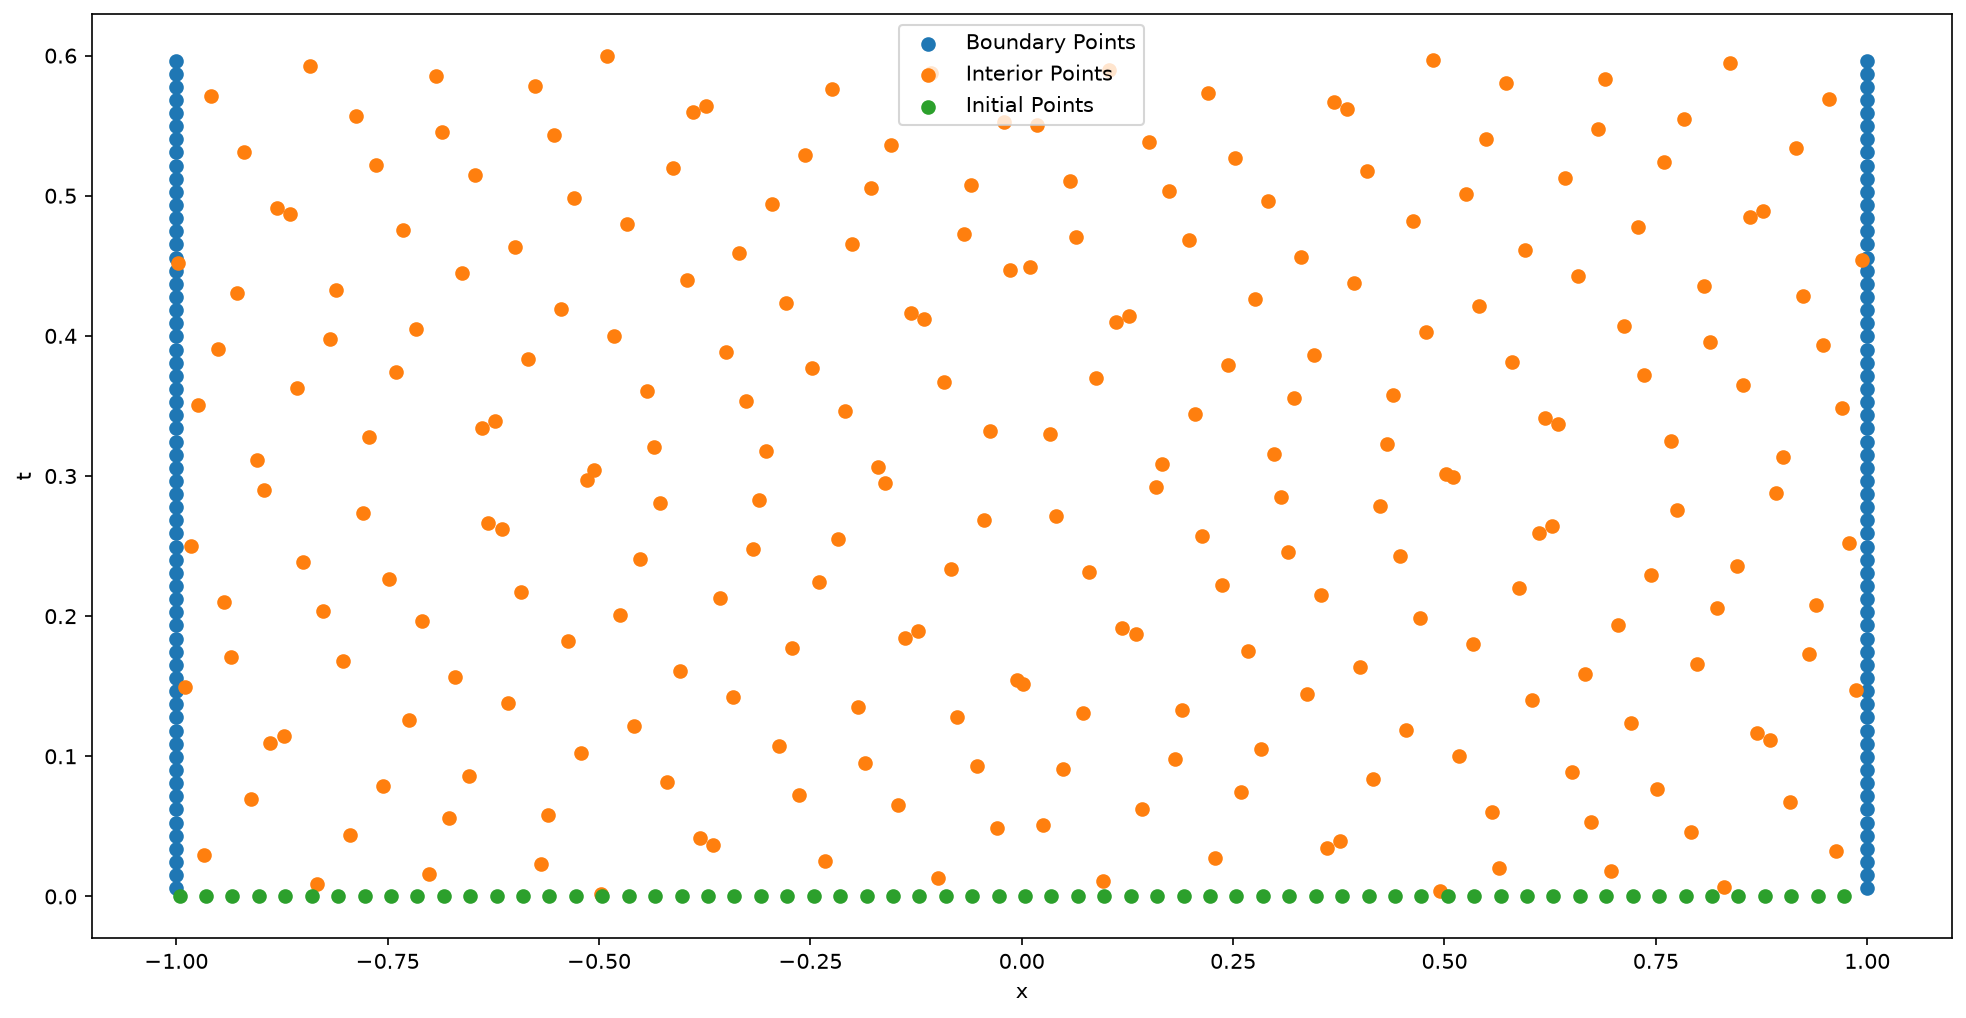

In [5]:
input_sb_, output_sb_ = pinn.add_spatial_boundary_points()
input_tb_, output_tb_ = pinn.add_temporal_boundary_points()
input_int_, output_int_ = pinn.add_interior_points()

plt.figure(figsize=(16, 8), dpi=150)
plt.scatter(input_sb_[:, 1].detach().numpy(), input_sb_[:, 0].detach().numpy(), label="Boundary Points")
plt.scatter(input_int_[:, 1].detach().numpy(), input_int_[:, 0].detach().numpy(), label="Interior Points")
plt.scatter(input_tb_[:, 1].detach().numpy(), input_tb_[:, 0].detach().numpy(), label="Initial Points")
plt.xlabel("x")
plt.ylabel("t")
plt.legend()
plt.show()

## Training

Default optimizer from the tutorial: **L-BFGS** with strong Wolfe line search.
One outer epoch due to L-BFGS running many internal iterations.

In [6]:
n_epochs = 1
optimizer_LBFGS = optim.LBFGS(
    pinn.approximate_solution.parameters(),
    lr=float(0.5),
    max_iter=50000,
    max_eval=50000,
    history_size=150,
    line_search_fn="strong_wolfe",
    tolerance_change=1.0 * np.finfo(float).eps,
)

  0%|          | 0/1 [00:00<?, ?it/s]/home/gustaw/nauka/eth/ai-for-science/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


step     0 | sb=1.26918 tb=0.76158 pde=16.11282 loss=1.56135, raw_loss=36.42048
step   100 | sb=0.00004 tb=0.00004 pde=0.01286 loss=-1.86479, raw_loss=0.01365
step   200 | sb=0.00001 tb=0.00000 pde=0.00089 loss=-3.00509, raw_loss=0.00099
step   300 | sb=0.00001 tb=0.00000 pde=0.00024 loss=-3.50020, raw_loss=0.00032
step   400 | sb=0.00000 tb=0.00000 pde=0.00011 loss=-3.78317, raw_loss=0.00016
step   500 | sb=0.00000 tb=0.00000 pde=0.00006 loss=-4.01998, raw_loss=0.00010
step   600 | sb=0.00000 tb=0.00000 pde=0.00003 loss=-4.26457, raw_loss=0.00005
step   700 | sb=0.00000 tb=0.00000 pde=0.00002 loss=-4.46877, raw_loss=0.00003
step   800 | sb=0.00000 tb=0.00000 pde=0.00002 loss=-4.59929, raw_loss=0.00003
step   900 | sb=0.00000 tb=0.00000 pde=0.00001 loss=-4.71249, raw_loss=0.00002
step  1000 | sb=0.00000 tb=0.00000 pde=0.00001 loss=-4.77566, raw_loss=0.00002
step  1100 | sb=0.00000 tb=0.00000 pde=0.00001 loss=-4.85256, raw_loss=0.00001
step  1200 | sb=0.00000 tb=0.00000 pde=0.00001 loss

100%|██████████| 1/1 [04:52<00:00, 292.06s/it]


Final Loss:  {'loss': -5.351049423217773, 'mse_sb': 6.883134062718455e-08, 'mse_tb': 9.349250262857822e-09, 'mse_pde': 3.674254003271926e-06, 'raw_loss': 4.456059741642093e-06}


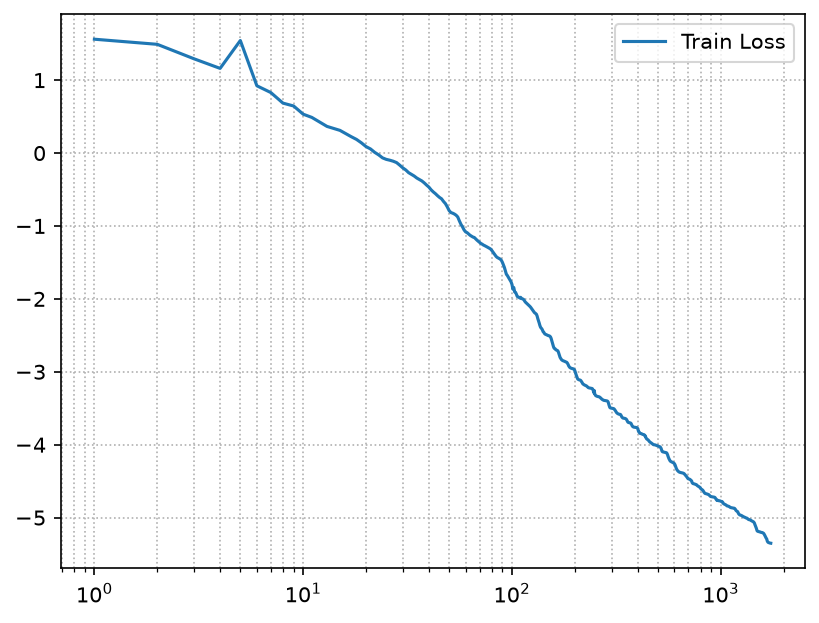

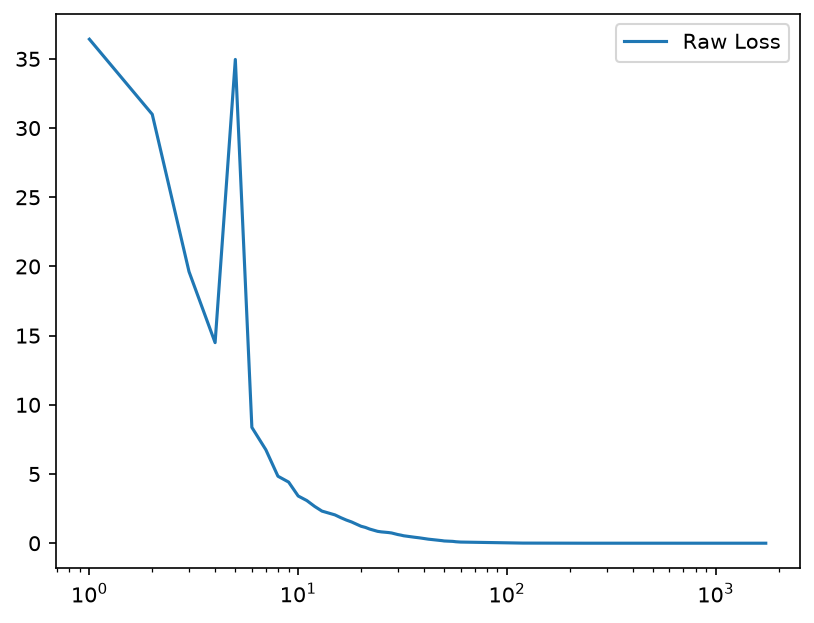

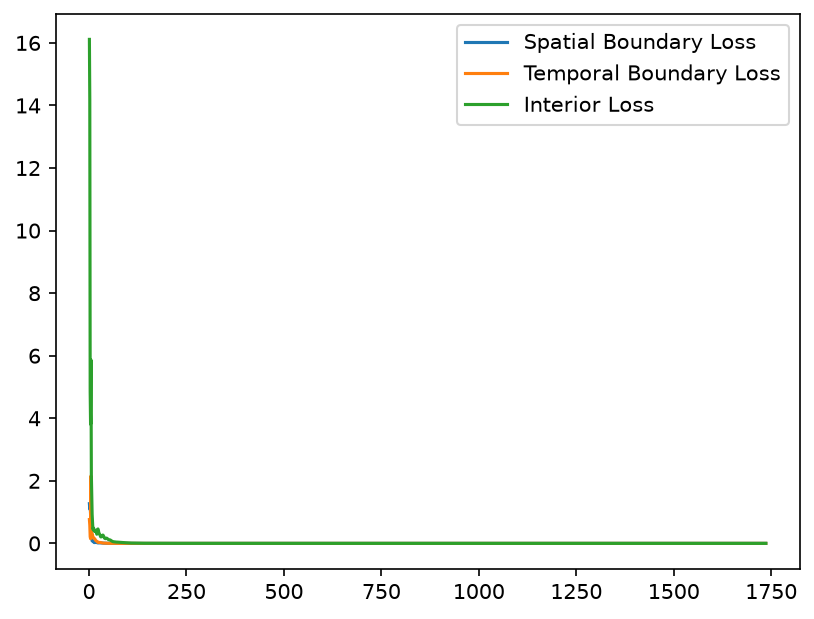

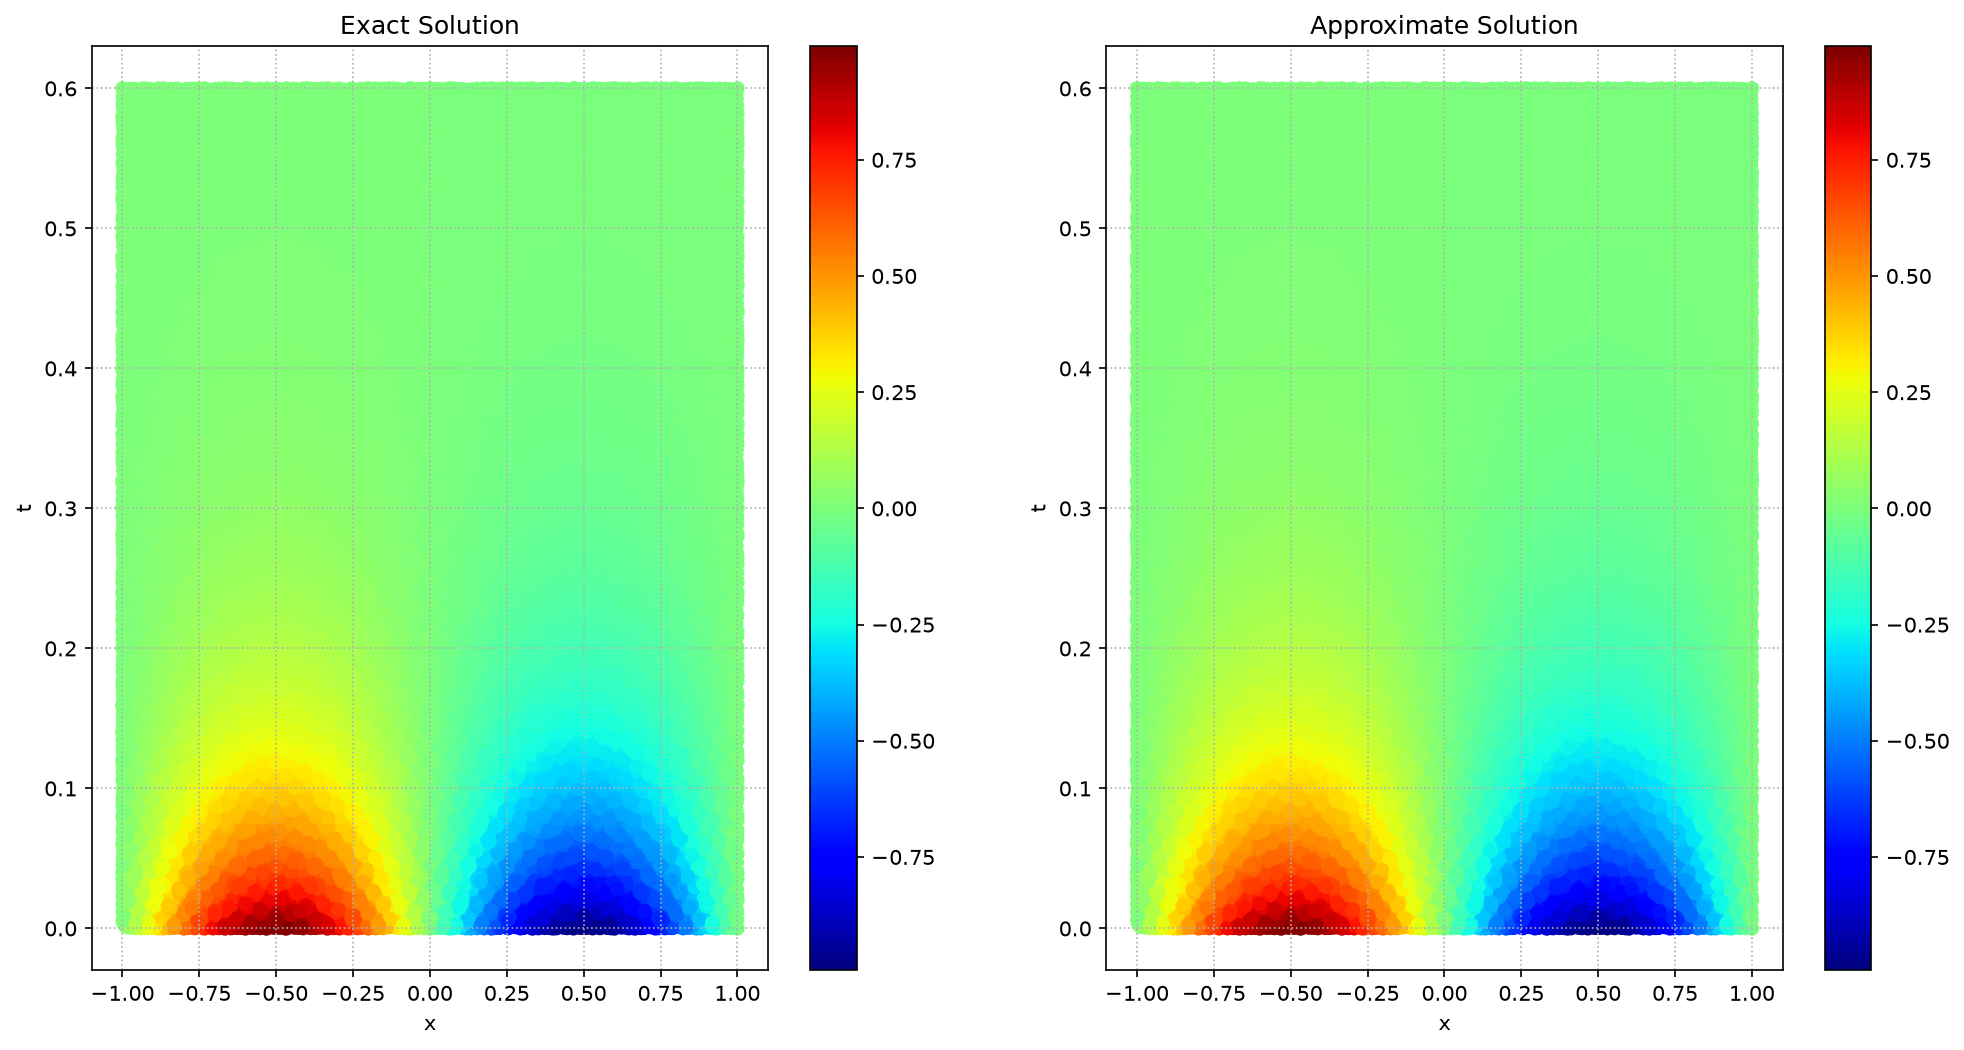

L2 Relative Error Norm:  0.0608694963157177 %


In [7]:
hist = pinn.fit(num_epochs=n_epochs, optimizer=optimizer_LBFGS, verbose=True)


pinn.plot_training_history(hist)
pinn.plot_solution()

---

# Further exploration

Two small questions on top of the tutorial setup. Every run uses the same
collocation points, the same initialization and the same L-BFGS settings;
only one setting changes at a time.

1. Does wrapping the loss in $\log_{10}$ change training?
2. How does the weight $\lambda_u$ of the boundary/initial terms affect the result?

The raw loss depends on $\lambda_u$, so runs with different weights are compared
with the relative $L^2$ error against the exact solution.

In [8]:
EXPERIMENT_SETUPS = {
    "baseline": {
        "use_log10_loss": True,
    },
    "no_log10": {
        "use_log10_loss": False,
    },
    "low_boundary_weight": {
        "use_log10_loss": True,
        "lambda_u": 1,
    },
    "high_boundary_weight": {
        "use_log10_loss": True,
        "lambda_u": 100,
    },
}

100%|██████████| 1/1 [05:59<00:00, 359.19s/it]


Final Loss:  {'loss': -5.498528957366943, 'mse_sb': 7.014043035269424e-08, 'mse_tb': 8.584972732705864e-09, 'mse_pde': 2.385755124123534e-06, 'raw_loss': 3.173009190504672e-06}


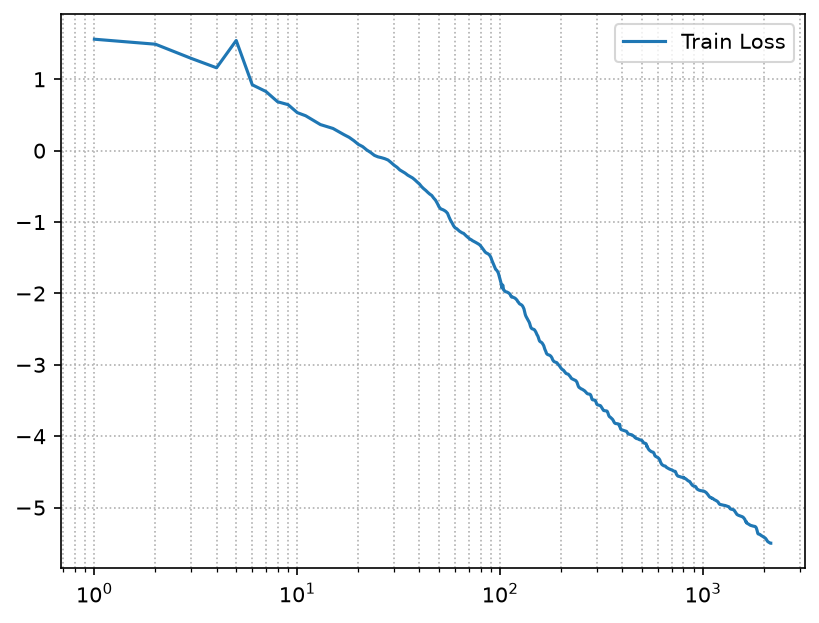

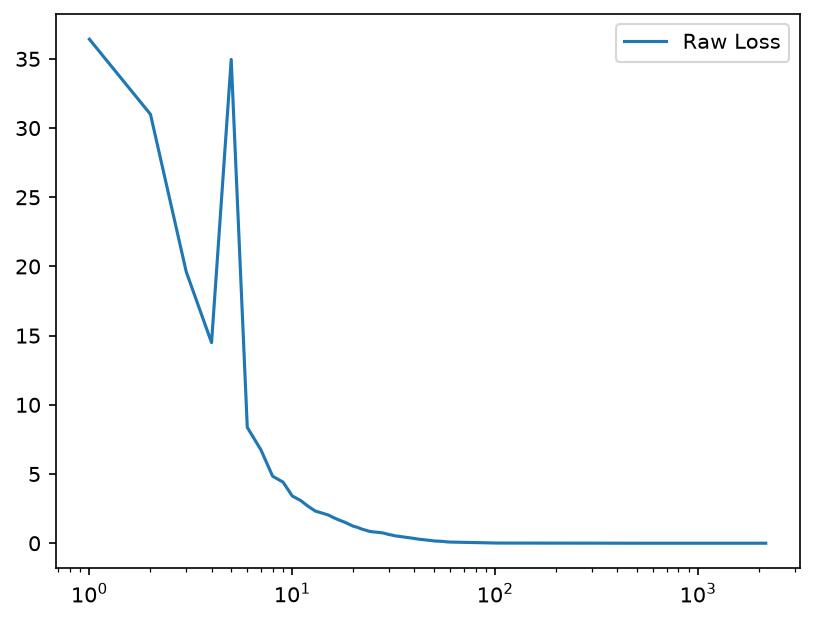

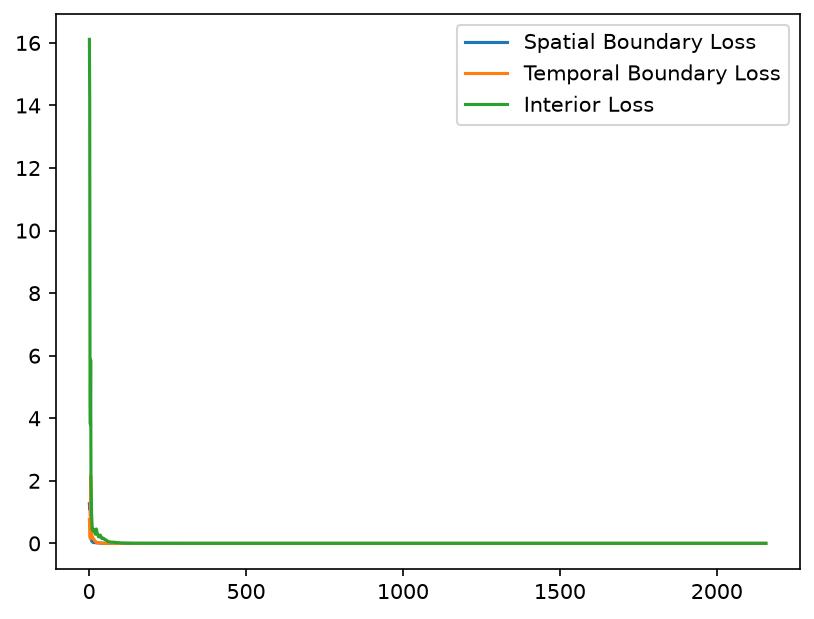

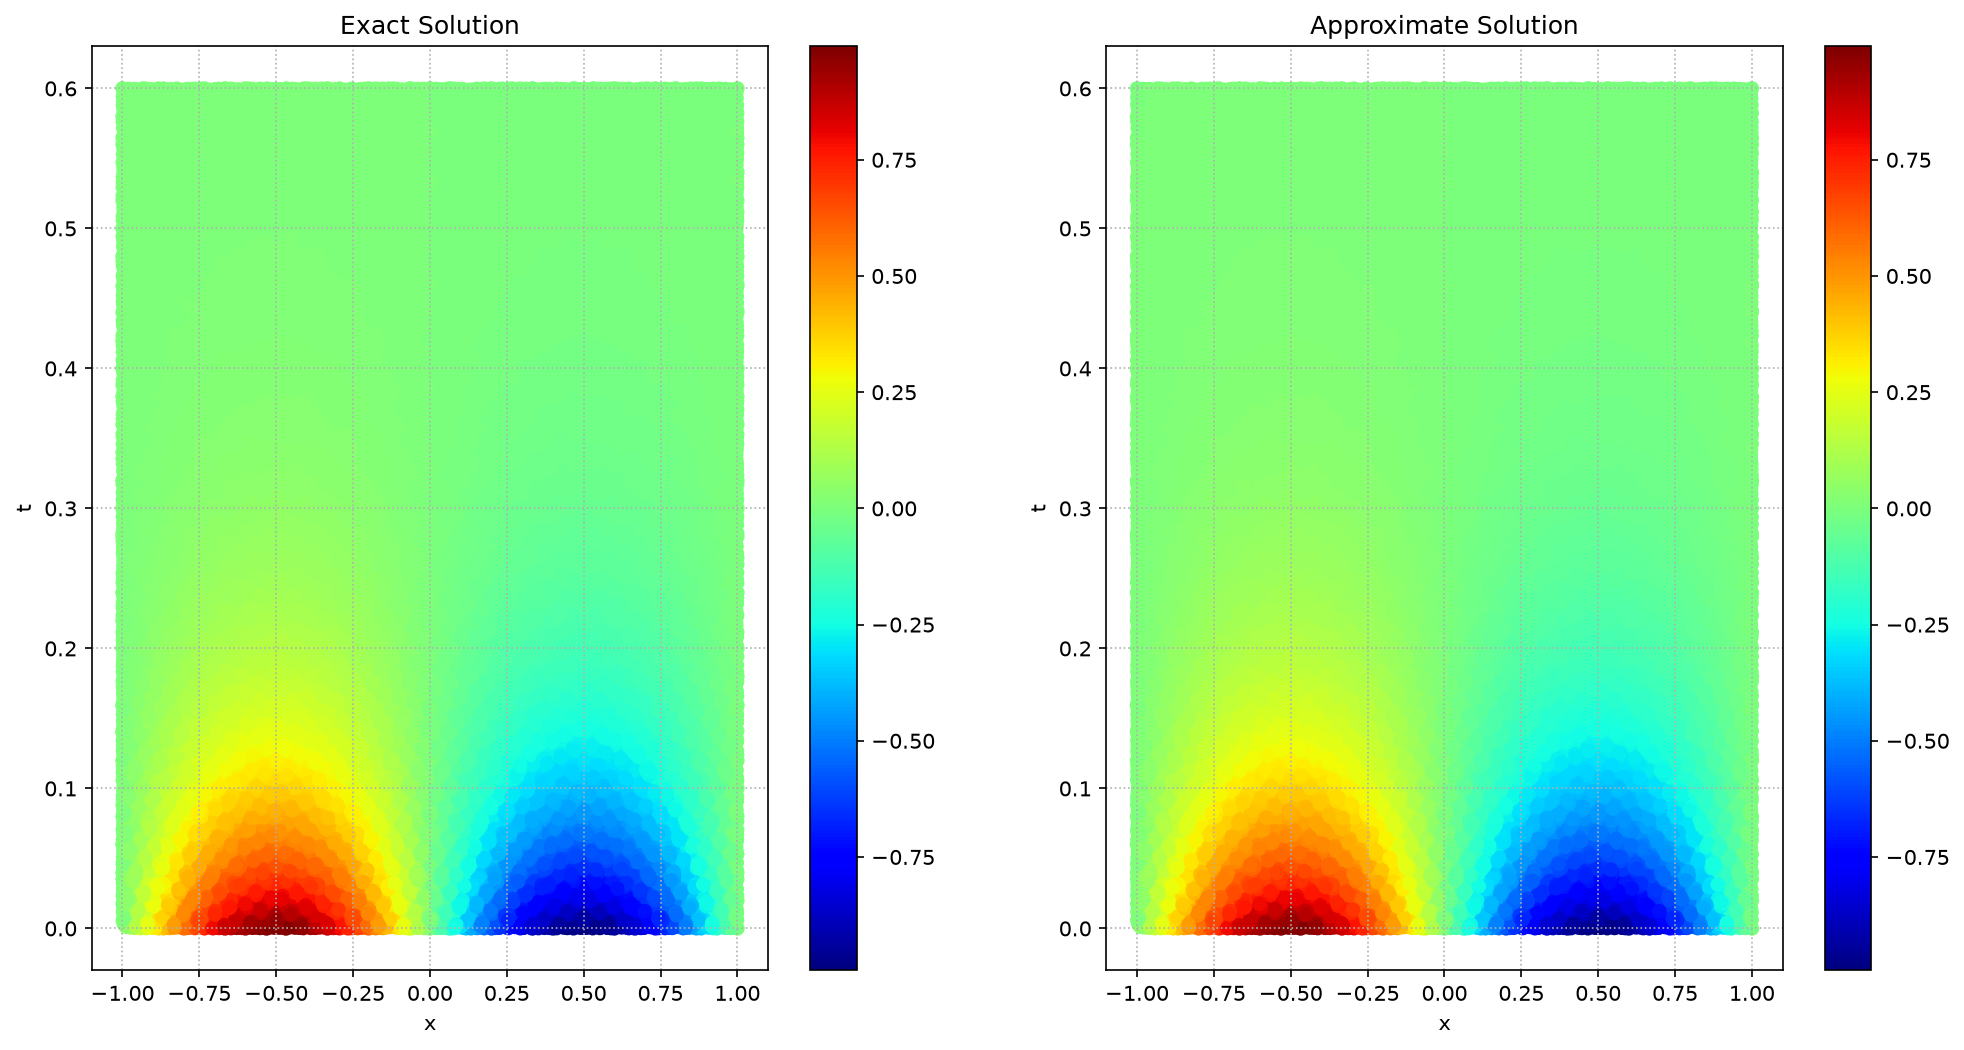

L2 Relative Error Norm:  0.05510757490992546 %


100%|██████████| 1/1 [01:58<00:00, 118.60s/it]


Final Loss:  {'loss': 5.578456239163643e-06, 'mse_sb': 1.3408771337708458e-07, 'mse_tb': 1.735828547566598e-08, 'mse_pde': 4.063996129843872e-06, 'raw_loss': 5.578456239163643e-06}


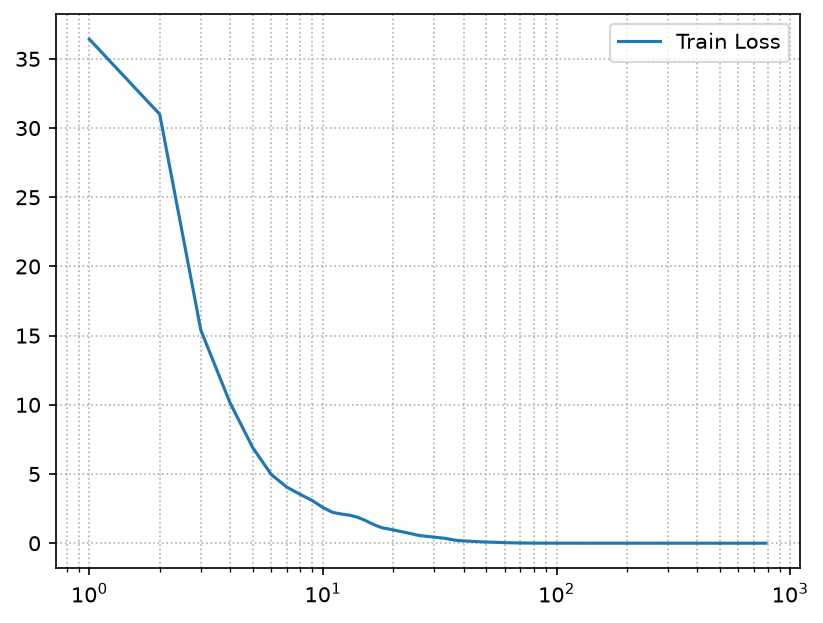

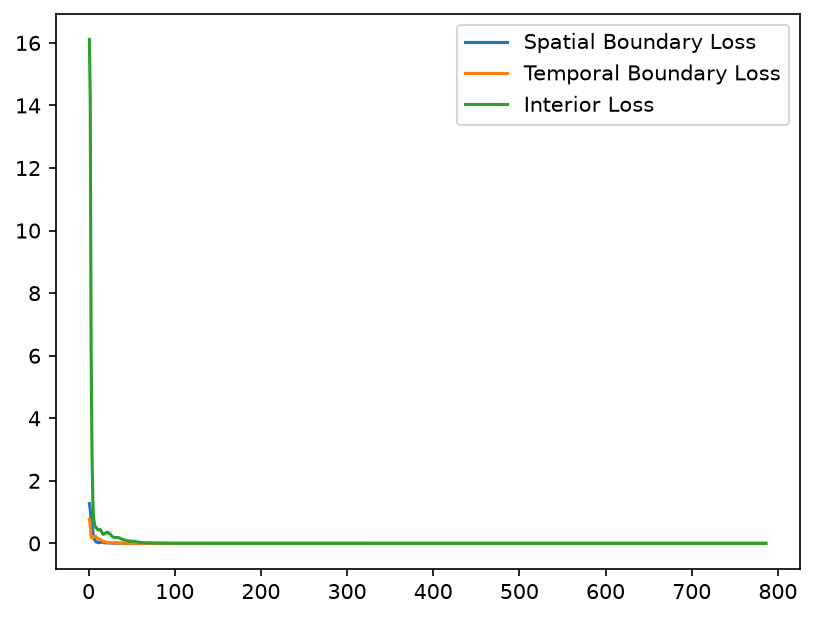

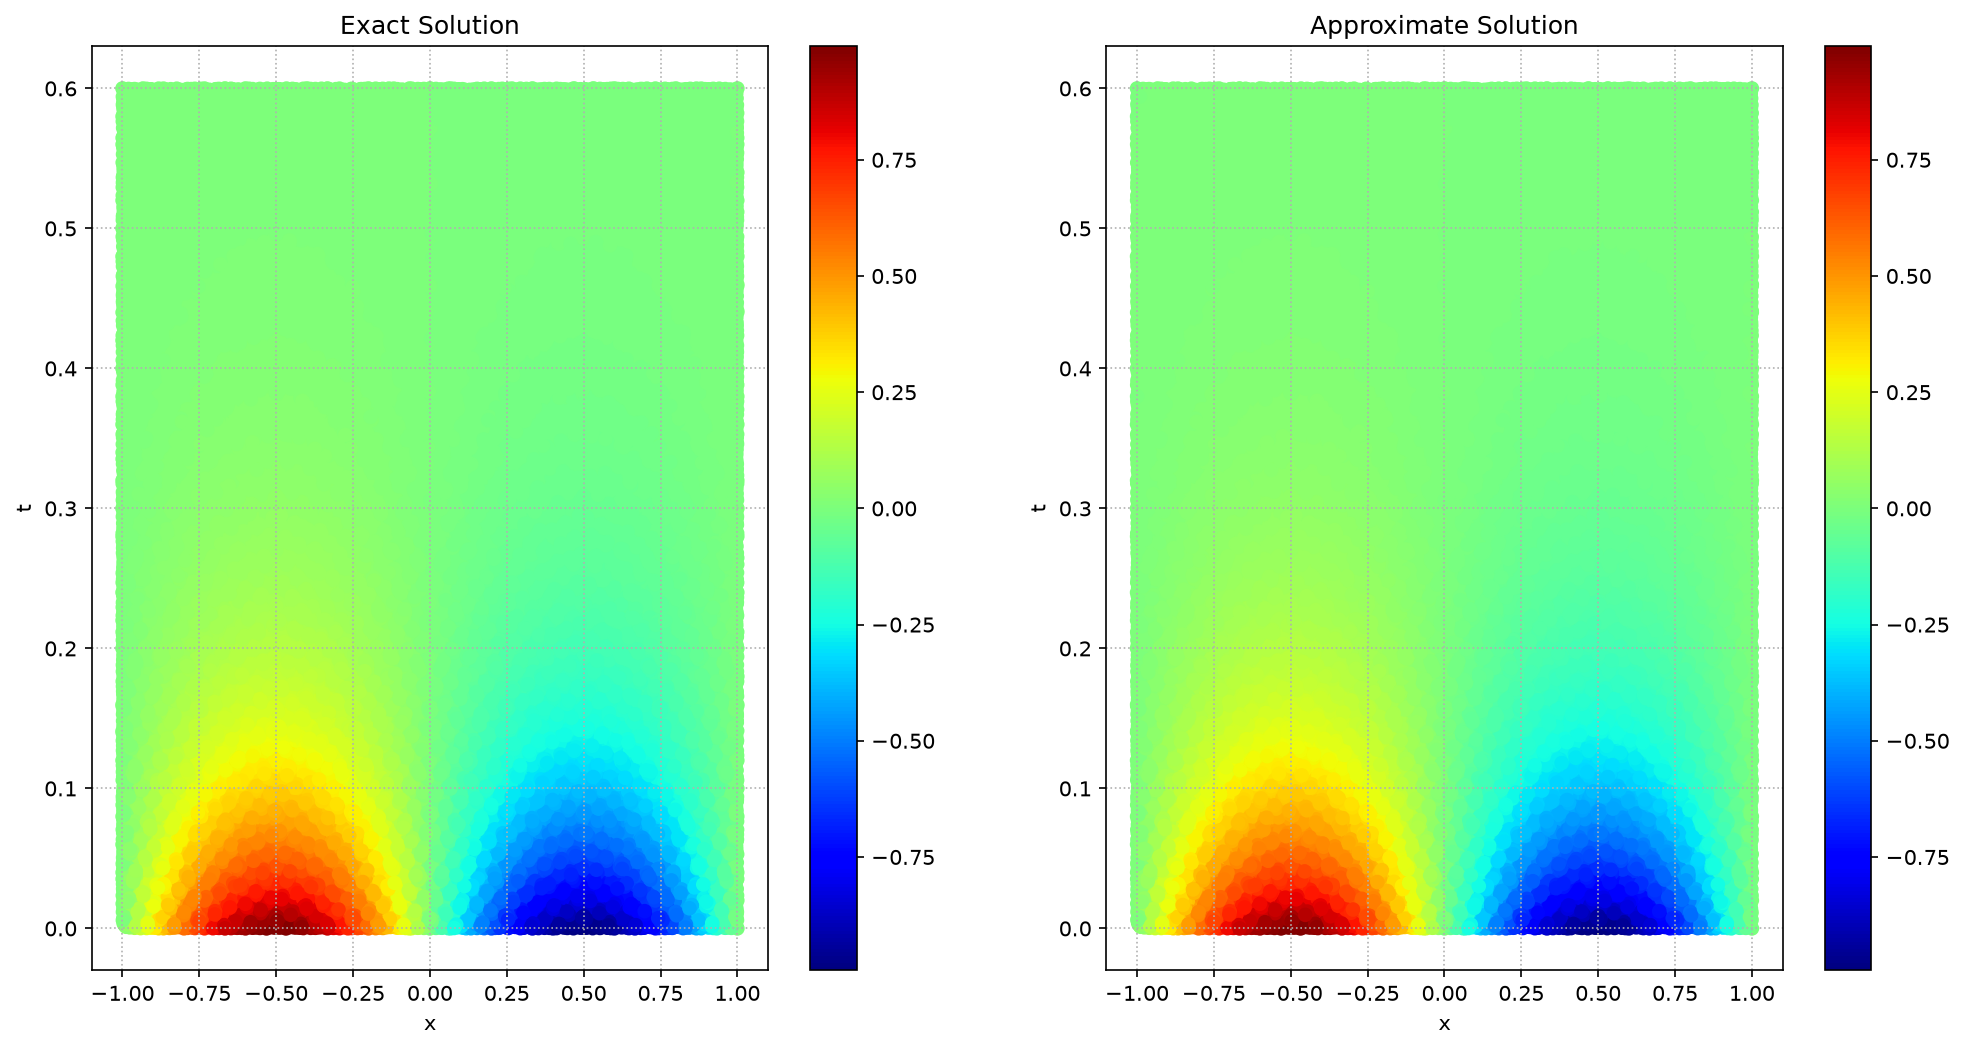

L2 Relative Error Norm:  0.07524196803569794 %


100%|██████████| 1/1 [05:06<00:00, 306.37s/it]


Final Loss:  {'loss': -6.0336127281188965, 'mse_sb': 1.2383119951664412e-07, 'mse_tb': 9.511420984154029e-08, 'mse_pde': 7.065784757287474e-07, 'raw_loss': 9.255238637706498e-07}


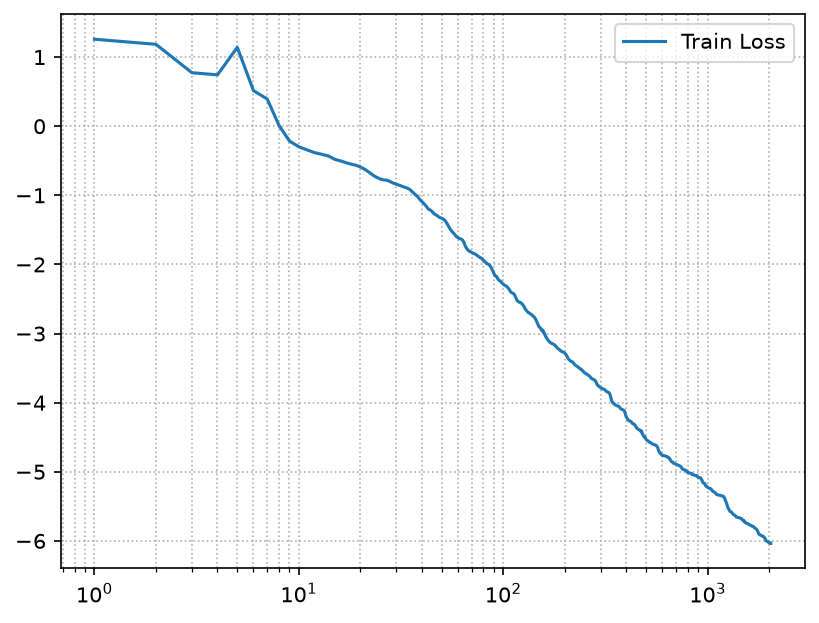

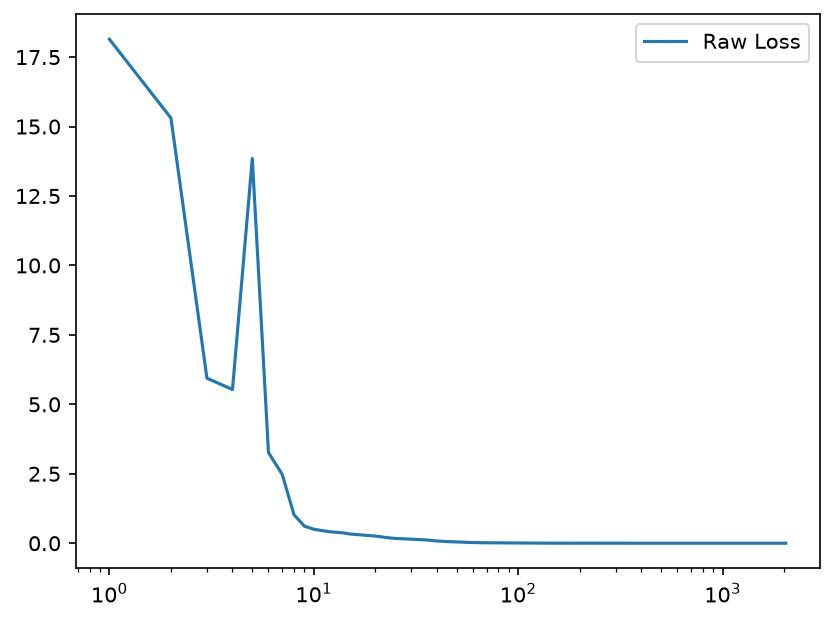

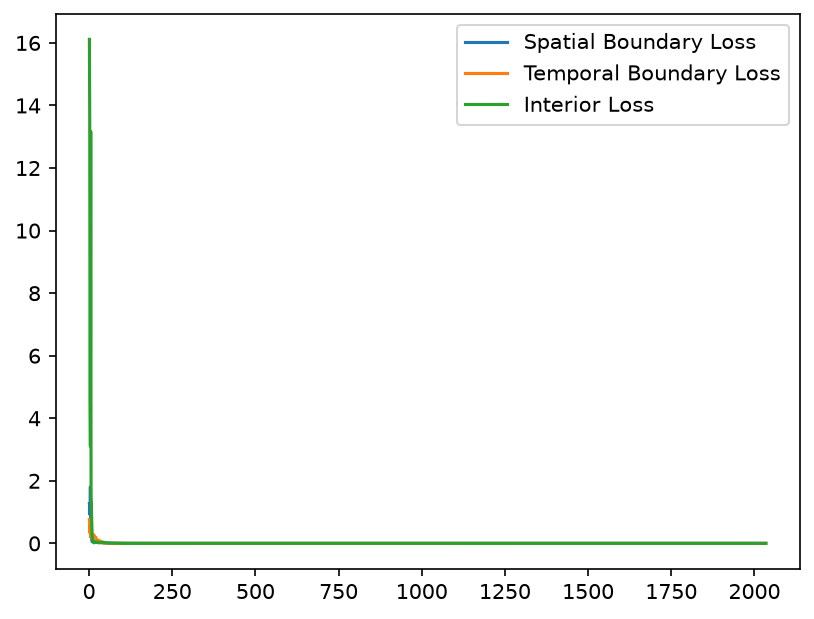

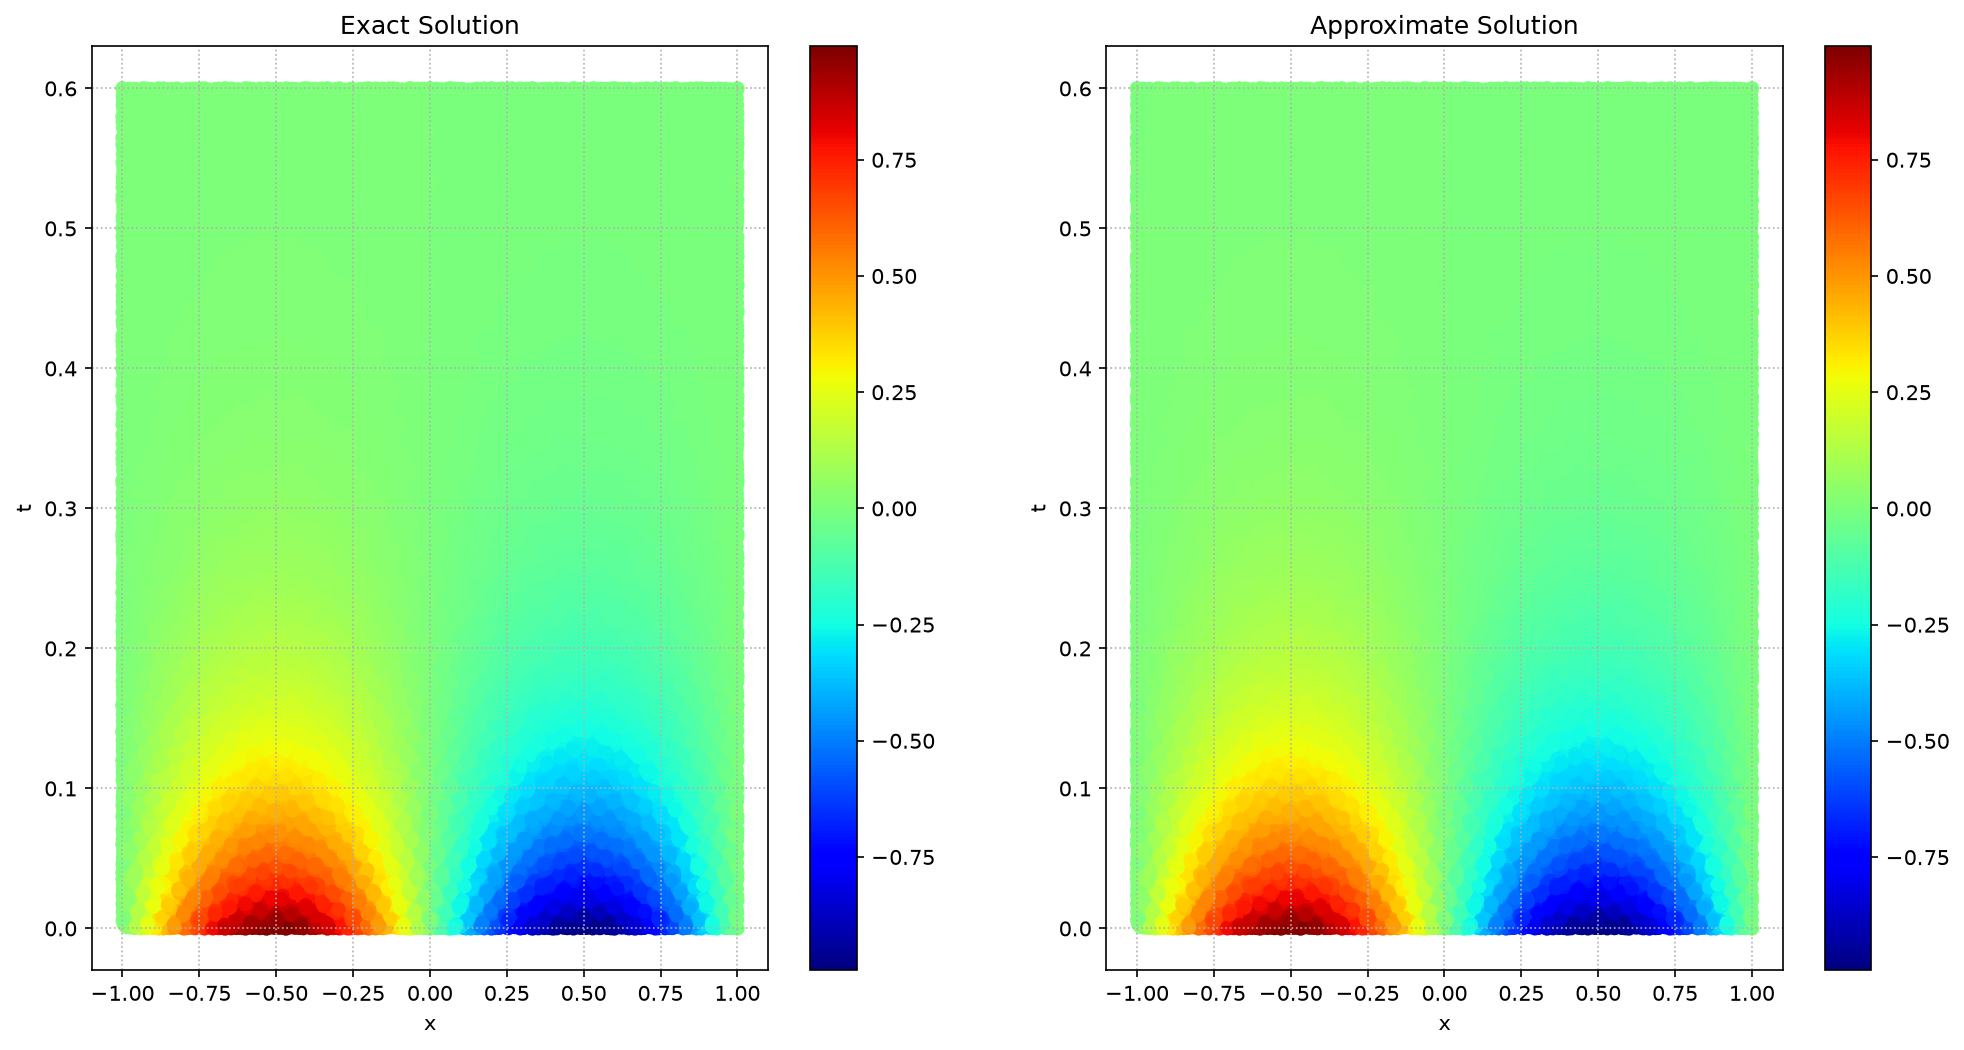

L2 Relative Error Norm:  0.07155716419219971 %


100%|██████████| 1/1 [04:34<00:00, 274.69s/it]


Final Loss:  {'loss': -4.908795356750488, 'mse_sb': 7.81431808150046e-09, 'mse_tb': 2.174502711227433e-08, 'mse_pde': 9.380929441249464e-06, 'raw_loss': 1.2336864529061131e-05}


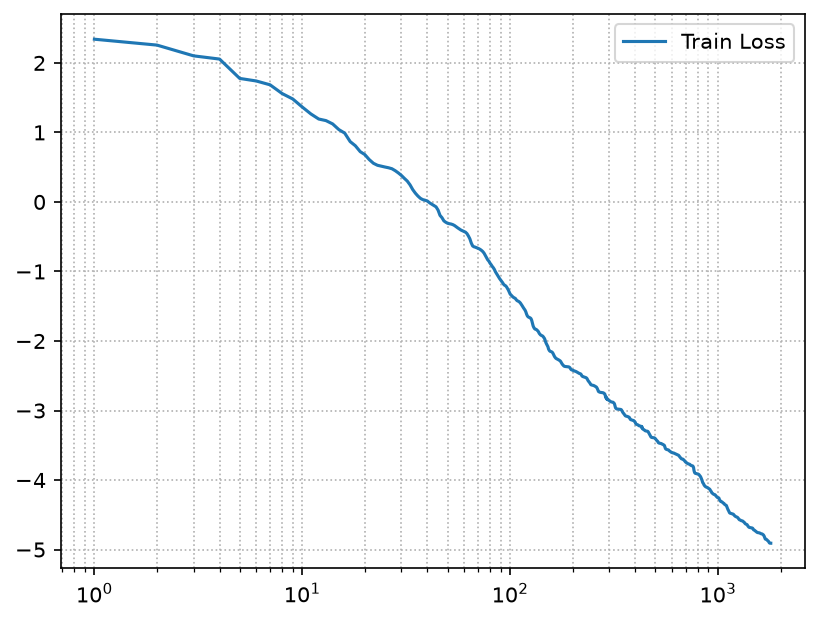

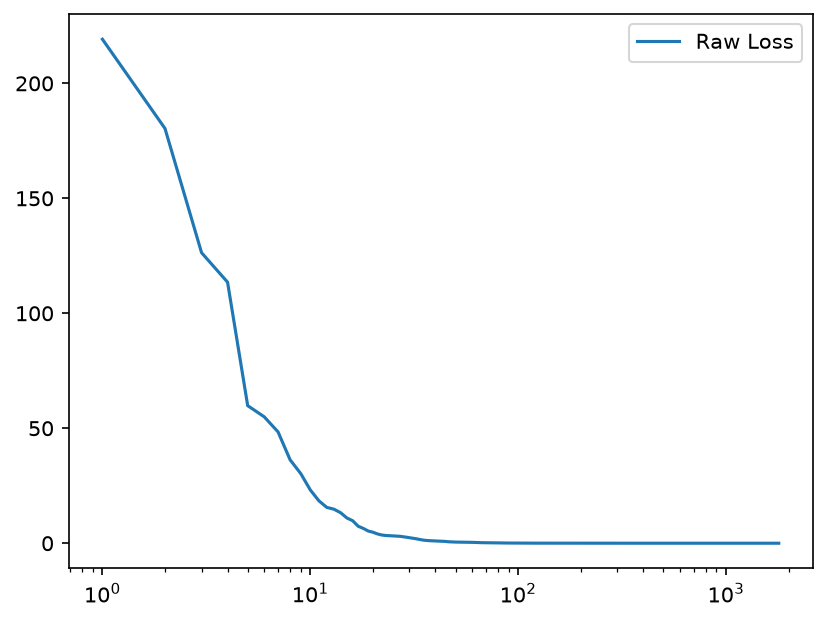

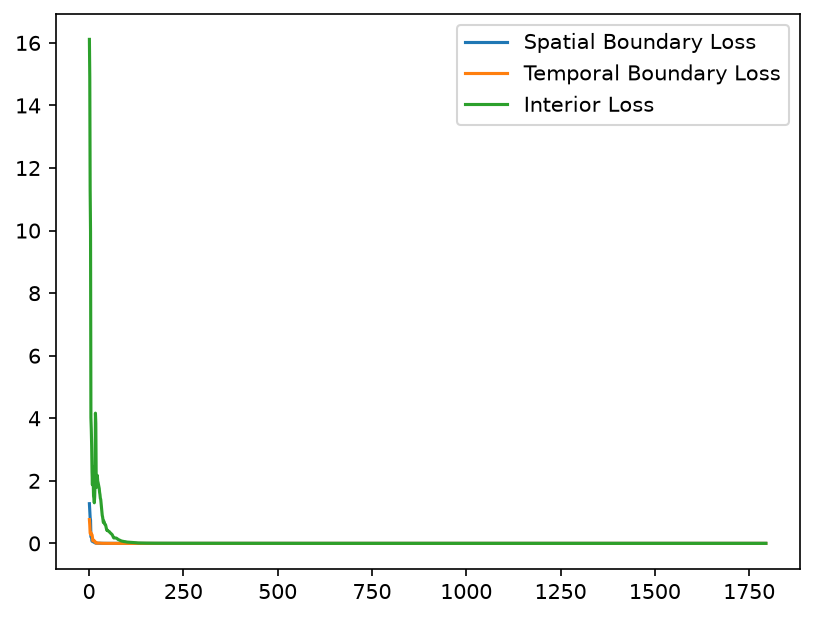

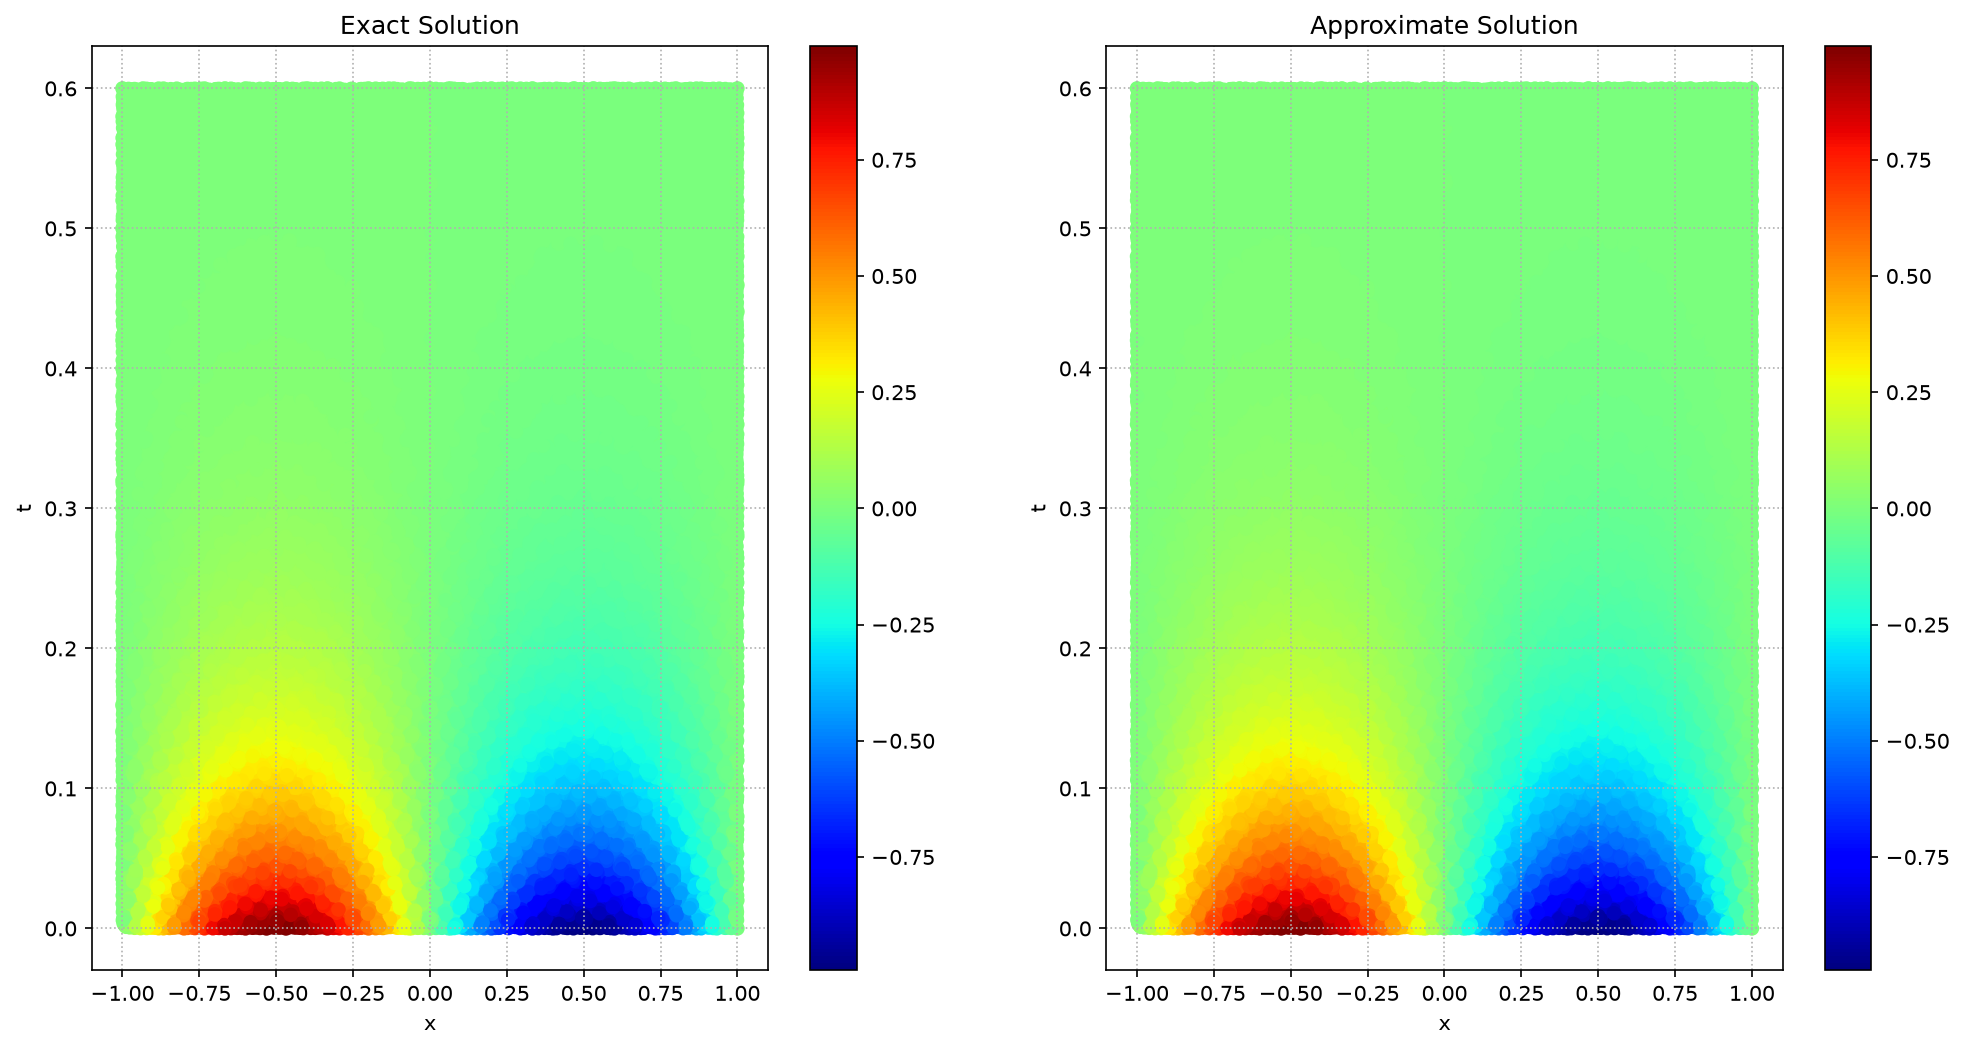

L2 Relative Error Norm:  0.047594279050827026 %


In [9]:
results = {}

for setup_name, setup in EXPERIMENT_SETUPS.items():
    pinn = PINN(n_int, n_sb, n_tb, **setup)
    optimizer = optim.LBFGS(
        pinn.approximate_solution.parameters(),
        lr=0.5,
        max_iter=50000,
        max_eval=50000,
        history_size=150,
        line_search_fn="strong_wolfe",
        tolerance_change=1.0 * np.finfo(float).eps,
    )

    hist = pinn.fit(num_epochs=1, optimizer=optimizer, verbose=False)
    results[setup_name] = {"history": hist, "model": pinn}
    pinn.plot_training_history(hist)
    pinn.plot_solution()

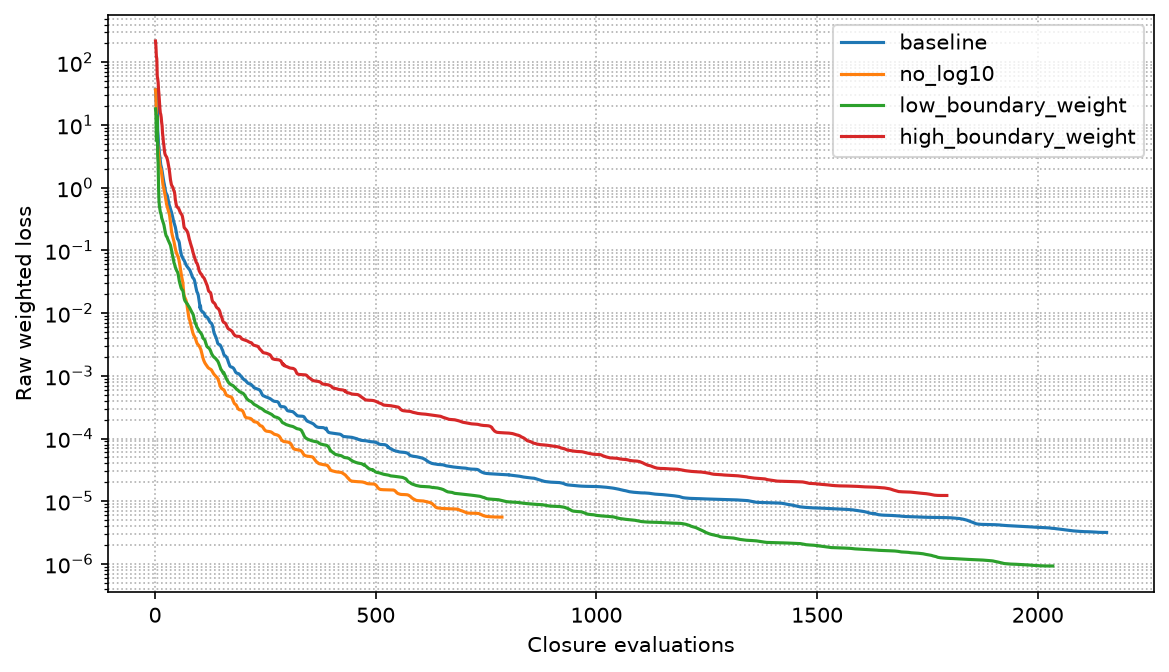

In [10]:
def plot_comparison(results):
    plt.figure(figsize=(9, 5), dpi=150)

    for name, result in results.items():
        history = result["history"]
        raw_losses = [h["raw_loss"] for h in history]

        plt.plot(
            np.arange(1, len(raw_losses) + 1),
            np.maximum(raw_losses, 1e-15),
            label=name,
        )

    plt.yscale("log")
    plt.xlabel("Closure evaluations")
    plt.ylabel("Raw weighted loss")
    plt.grid(True, which="both", ls=":")
    plt.legend()
    plt.show()


plot_comparison(results)

In [11]:
eval_points = torch.quasirandom.SobolEngine(dimension=2).draw(10000)

eval_points = results["baseline"]["model"].convert(eval_points)

for name, result in results.items():
    error = result["model"].evaluate(eval_points)
    print(f"{name:20s} | Relative L2 error: {error:.3f}%")

baseline             | Relative L2 error: 0.055%
no_log10             | Relative L2 error: 0.075%
low_boundary_weight  | Relative L2 error: 0.072%
high_boundary_weight | Relative L2 error: 0.048%


## Observations

- **All variants end up with practically the same accuracy** (relative $L^2$ error
  0.048–0.075%). Running the baseline twice already gives 0.061% vs 0.055%
  (probably GPU non-determinism), so most of these differences are within run-to-run noise.
  For this simple problem the tutorial setup is already well tuned.

- **`log10` mostly changes *when* L-BFGS stops.** Without it the run stopped after
  ~800 closure evaluations (≈2 min instead of ≈5) with a higher final loss and a
  slightly worse error. The likely reason: the raw loss gets so small (~1e-6) that the
  gradient hits L-BFGS's `tolerance_grad`. With $\log_{10}$ the gradient is
  rescaled by $1/(L \ln 10)$, so the optimizer keeps making progress.

- **Higher $\lambda_u$ (100) gave the lowest error and the smoothest loss curve**,
  even though its PDE residual was the largest. For the heat equation,
  fitting the initial/boundary data accurately seems to matter more than squeezing the
  interior residual. With a single run per setting I wouldn't over-interpret this.